In [18]:
import numpy as np 
import matplotlib.pyplot as plt
import control as ct
import scipy.signal as signal

In [19]:
K = 1.06
G1 = ct.tf([1], [1, 0])
G2 = ct.tf([1], [1, 1])
G3 = ct.tf([1], [1, 2])

# Gain of the system K 
print(f'The gain of the system K: {K}')

# Actual Plant 
G = K * G1 * G2 * G3
print(f'The transfer function of the system G(s): {G}')

# Feedback Loop Transfer Function
H = 1 
print(f'The transfer function of the feedback loop H(s): {H}')

# Open Loop Transfer Funtion 
L = G * H
print(f'The transfer function of the open loop system L(s): {L}')

# Closed Loop Transfer Funtion
CL = ct.feedback(G, H)
print(f'The transfer function of the closed loop system CL(s): {CL}')

The gain of the system K: 1.06
The transfer function of the system G(s): <TransferFunction>: sys[44]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

        1.06
  -----------------
  s^3 + 3 s^2 + 2 s
The transfer function of the feedback loop H(s): 1
The transfer function of the open loop system L(s): <TransferFunction>: sys[46]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

        1.06
  -----------------
  s^3 + 3 s^2 + 2 s
The transfer function of the closed loop system CL(s): <TransferFunction>: sys[48]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

            1.06
  ------------------------
  s^3 + 3 s^2 + 2 s + 1.06


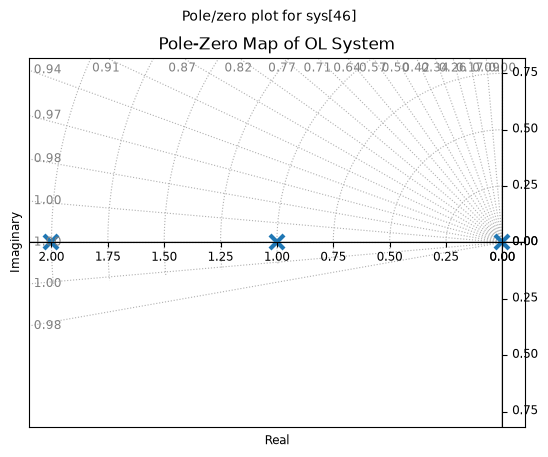

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


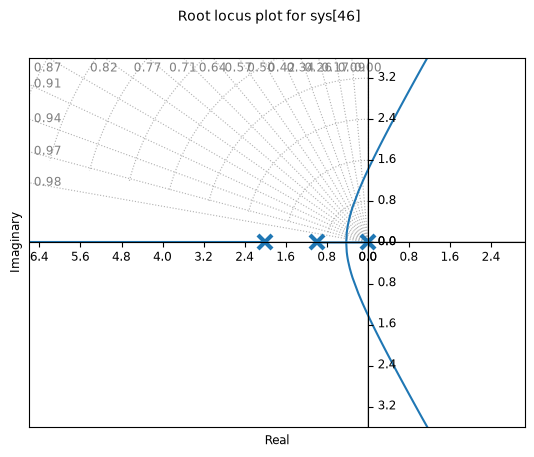

DC gain for OL= inf
Zeros of OL= []
Poles of OL= [-2.+0.j -1.+0.j  0.+0.j]
Dominant stable OL pole(s): [-1.+0.j]
Dominant OL pole (p1) = (-1+0j)
Dominant OL pole (p1) in abs value = 1.0


In [20]:
# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(L, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of OL System")
plt.show()

# Root locus = drawn for open loop system to see closed loop poles location at s plane
ct.root_locus(L, grid=True, marker_size=10, marker_width=3) 
plt.show()

# DC gain 
dc = ct.dcgain(L)
print(f'DC gain for OL= {dc}')
# Zeros 
z = ct.zeros(L)
print(f'Zeros of OL= {z}')
# Poles 
p = ct.poles(L)
print(f'Poles of OL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable OL pole(s):", dominant_poles)

p1 = dominant_poles[0]
p_do = dominant_poles[0]
print(f'Dominant OL pole (p1) = {p1}')
print(f'Dominant OL pole (p1) in abs value = {np.abs(p1)}')

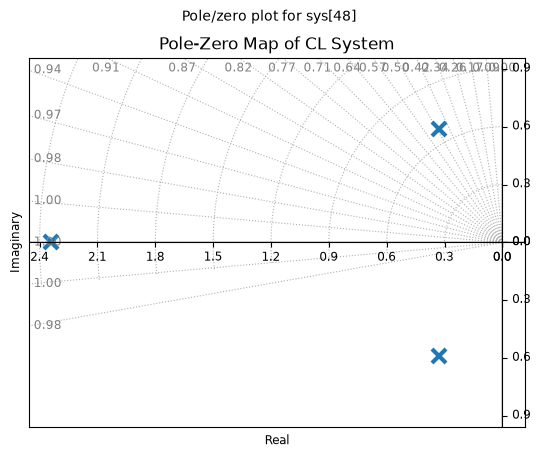

DC gain for CL= 1.0
Zeros of CL= []
Poles of CL= [-2.33860677+0.j         -0.33069661+0.58643079j -0.33069661-0.58643079j]
    Eigenvalue (pole)       Damping     Frequency
               -2.339             1         2.339
   -0.3307   +0.5864j        0.4912        0.6732
   -0.3307   -0.5864j        0.4912        0.6732
Natural frequency of poles (Wn) = [2.33860677 0.67324685 0.67324685]
Damping ratio zeta of poles (Z) = [1.         0.49119667 0.49119667]
Poles = [-2.33860677+0.j         -0.33069661+0.58643079j -0.33069661-0.58643079j]
Poles of CL= [-2.33860677+0.j         -0.33069661+0.58643079j -0.33069661-0.58643079j]
Dominant stable CL pole(s): [-0.33069661+0.58643079j -0.33069661-0.58643079j]
Dominant CL pole (p1) = (-0.3306966126132147+0.5864307914002096j)
Dominant CL pole (p1) in abs value = 0.673246851233729


Dominant Pole: (-0.3306966126132147+0.5864307914002096j)
Natural frequency (wn): 0.673246851233729 rad/s
Damping ratio (zeta, z): 0.49119667178125104
Decay rate (sigma):

In [21]:
# closed loop poles and zeros analysis 

# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(CL, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of CL System")
plt.show()

# DC gain 
dc = ct.dcgain(CL)
print(f'DC gain for CL= {dc}')
# Zeros 
z = ct.zeros(CL)
print(f'Zeros of CL= {z}')
# Poles 
p = ct.poles(CL)
print(f'Poles of CL= {p}')

# Print exact transient metrics derived from poles 
wn, zeta, poles = ct.damp(CL)
print(f'Natural frequency of poles (Wn) = {wn}')
print(f'Damping ratio zeta of poles (Z) = {zeta}')
print(f'Poles = {poles}')

# To find the dominant pole(s) of a control system plant, 
# you identify the poles (the roots of the denominator of the transfer function) that lie closest to the imaginary (jw) axis 
# or the origin in the s-plane, 
# provided other poles are sufficiently far away
print(f'Poles of CL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable CL pole(s):", dominant_poles)

p1 = dominant_poles[0]
p_d = dominant_poles[0]
print(f'Dominant CL pole (p1) = {p1}')
print(f'Dominant CL pole (p1) in abs value = {np.abs(p1)}')
print('\n')

wn = abs(p1)                  # Natural frequency (rad/s)
zeta = -np.real(p1) / wn     # Damping ratio
sigma = -np.real(p1)         # Decay rate (1/s)
wd = abs(np.imag(p1))        # Damped frequency (rad/s)

print("Dominant Pole:", p1)
print("Natural frequency (wn):", wn, "rad/s")
print("Damping ratio (zeta, z):", zeta)
print("Decay rate (sigma):", sigma, "1/s")
print("Damped frequency (wd):", wd, "rad/s")




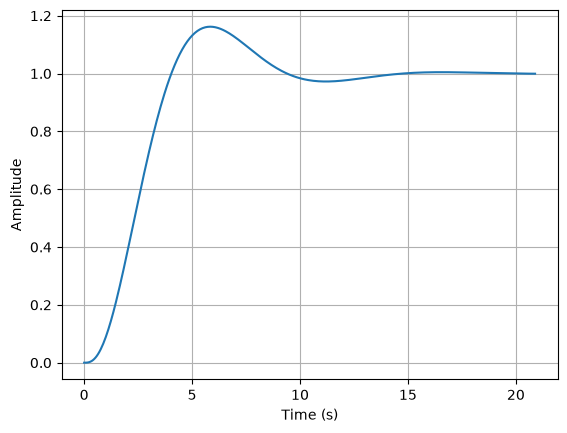

Rise Time (Tr): 2.54 seconds
Settling Time (Ts): 12.51 seconds
Peak Time (Tp): 5.84 seconds
Overshoot (%): 16.20%
Final Value = 1.0
Steasy state error (ess) = 0.0


In [22]:
plt.figure()
t, y = ct.step_response(CL)

plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# transient characteristics
info = ct.step_info(CL)
final_value = info['SteadyStateValue']
ess = 1 - final_value


print(f"Rise Time (Tr): {info['RiseTime']:.2f} seconds")
print(f"Settling Time (Ts): {info['SettlingTime']:.2f} seconds")
print(f"Peak Time (Tp): {info['PeakTime']:.2f} seconds")
print(f"Overshoot (%): {info['Overshoot']:.2f}%")
# print(f"Undershoot (%): {info['Undershoot']:.2f}%")
print(f'Final Value = {info["SteadyStateValue"]}')
print(f'Steasy state error (ess) = {ess}')

In [23]:
# Type of the system = 1 
# So, Kv is specified, Kv = lim:s->0 sG(s)Gc(s) 

A1 = K*G2*G3
Kv_old = np.abs(A1(0))
print(f'Old velocity error constant (Kv_old) = {Kv_old}')

ess_old = 1/Kv_old
print(f'Old error (ess) = {ess_old}')

Old velocity error constant (Kv_old) = 0.53
Old error (ess) = 1.8867924528301885


In [24]:
# Required Specification 
# ess = 0.01 

In [25]:
# Type of the system = 1 
# So, Kv is specified, Kv = lim:s->0 sG(s)Gc(s)

ess_new = 0.01 
print(f'Required error (ess) = {ess_new}')
Kv_new = 1 / ess_new
print(f'Required velocity error constant (Kv_new) = {Kv_new}')

Required error (ess) = 0.01
Required velocity error constant (Kv_new) = 100.0


In [26]:
beta = Kv_new / Kv_old
print(f'Beta = {beta}')

# Nearest open loop pole
# -1/T = 10% of the nearest open or close loop pole
# P_do  np.real(p_do)
T = -1/(0.1*np.real(p_do))
print(f'T = {T}')

zc = 1/T
print(f'Zero of the lag compensator (zc) = {zc}')
pc = 1/(T*beta)
print(f'Pole of the lag compensator (pc) = {pc}')

# Lag Compensator transfer function without gain 
Gc = ct.tf([1, zc], [1, pc])
print(f'Lead Compensator Transfer Function without gain (Gc) = {Gc}')

# |Gc(s)| = 1 and -5 < angle(Gc(s)) < 0 
print(f'Open Loop Gain at required Pole Gc(Sd) = {Gc(p_do)}')
print(f'Open Loop Gain at required Pole in absolute form Gc(Sd) = {np.abs(Gc(p_do))}')
print(f'Open Loop Phase at required Pole Gc(Sd) = {np.angle(Gc(p_do))}')
print(f'Open Loop Phase at required Pole in Degrees Gc(Sd) = {np.rad2deg(np.angle(Gc(p_do)))}')

Beta = 188.67924528301887
T = 10.0
Zero of the lag compensator (zc) = 0.1
Pole of the lag compensator (pc) = 0.00053
Lead Compensator Transfer Function without gain (Gc) = <TransferFunction>: sys[56]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

    s + 0.1
  -----------
  s + 0.00053
Open Loop Gain at required Pole Gc(Sd) = (0.9004772529440604-0j)
Open Loop Gain at required Pole in absolute form Gc(Sd) = 0.9004772529440604
Open Loop Phase at required Pole Gc(Sd) = -0.0
Open Loop Phase at required Pole in Degrees Gc(Sd) = -0.0


In [27]:
# Lead compensator gain 
Kc = 1/(np.abs(G(p_d)*Gc(p_d)))
print(f'Lead Compensator Gain (Kc) = {Kc}')

Lead Compensator Gain (Kc) = 1.0679341931172623


In [28]:
Gc1 = Kc * Gc
print(f'Lead Compensator Transfer Function with gain (Gc1) = {Gc1}')

# |Gc(s)| = 1 and -5 < angle(Gc(s)) < 0 
print(f'Open Loop Gain at required Pole G(Sd) = {Gc(p_d)}')
print(f'Open Loop Gain at required Pole in absolute form G(Sd) = {np.abs(Gc(p_d))}')
print(f'Open Loop Phase at required Pole G(Sd) = {np.angle(Gc(p_d))}')
print(f'Open Loop Phase at required Pole in Degrees G(Sd) = {np.rad2deg(np.angle(Gc(p_d)))}')

Lead Compensator Transfer Function with gain (Gc1) = <TransferFunction>: sys[58]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

  1.068 s + 0.1068
  ----------------
    s + 0.00053
Open Loop Gain at required Pole G(Sd) = (0.9274875897697621-0.12879409514211182j)
Open Loop Gain at required Pole in absolute form G(Sd) = 0.9363872853261078
Open Loop Phase at required Pole G(Sd) = -0.1379810328942967
Open Loop Phase at required Pole in Degrees G(Sd) = -7.905730837698982


In [29]:
A2 = K*G2*G3*Gc1 
# Type of system = 1 i.e. pole at origin = 1 
# so the velocity error constant, Kv = lim:s->0 sG(s)Gc(s)
kv = np.abs(A2(0))
print(f'velocity error constant kv = {kv}')

ess = 1/kv
print(f'steady state error ess = {ess}')

velocity error constant kv = 106.79341931172624
steady state error ess = 0.009363872853261072


In [30]:
A3 = G*Gc1 
print(f'System Transfer Function with compensator A3(s) = {A3}')
A4 = A3 * H
print(f'open loop system transfer function with compensator A4(s) = {A4}')
A5 = ct.feedback(A3, 1)
print(f'Closed loop system transfer function with compensator A5(s) = {A5}')

System Transfer Function with compensator A3(s) = <TransferFunction>: sys[63]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

             1.132 s + 0.1132
  ---------------------------------------
  s^4 + 3.001 s^3 + 2.002 s^2 + 0.00106 s
open loop system transfer function with compensator A4(s) = <TransferFunction>: sys[65]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

             1.132 s + 0.1132
  ---------------------------------------
  s^4 + 3.001 s^3 + 2.002 s^2 + 0.00106 s
Closed loop system transfer function with compensator A5(s) = <TransferFunction>: sys[67]
Inputs (1): ['u[0]']
Outputs (1): ['y[0]']

                 1.132 s + 0.1132
  ----------------------------------------------
  s^4 + 3.001 s^3 + 2.002 s^2 + 1.133 s + 0.1132


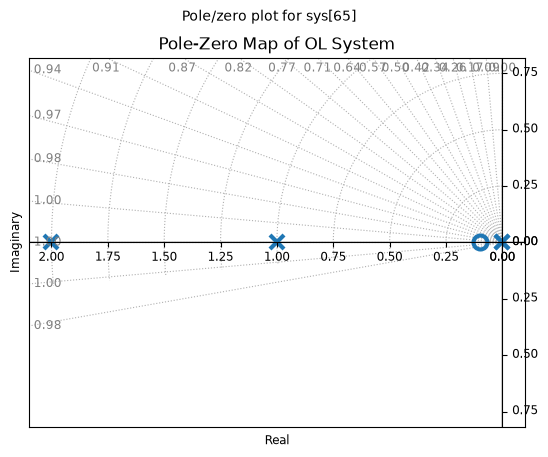

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


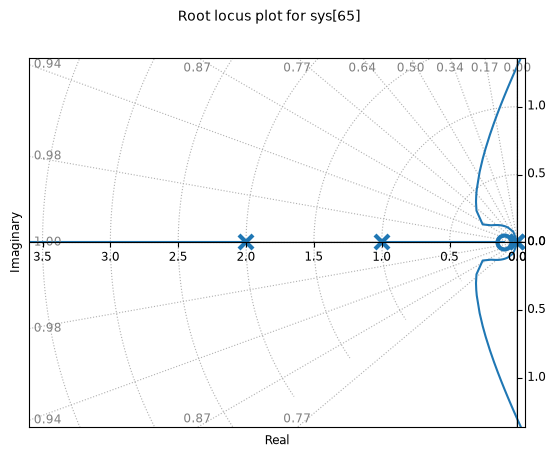

DC gain for OL= inf
Zeros of OL= [-0.1+0.j]
Poles of OL= [-2.0e+00+0.j -1.0e+00+0.j -5.3e-04+0.j  0.0e+00+0.j]
Dominant stable OL pole(s): [-0.00053+0.j]
Dominant OL pole (p1) = (-0.00053+0j)
Dominant OL pole (p1) in abs value = 0.00053


In [31]:
# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(A4, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of OL System")
plt.show()

# Root locus = drawn for open loop system to see closed loop poles location at s plane
ct.root_locus(A4, grid=True, marker_size=10, marker_width=3) 
plt.show()

# DC gain 
dc = ct.dcgain(A4)
print(f'DC gain for OL= {dc}')
# Zeros 
z = ct.zeros(A4)
print(f'Zeros of OL= {z}')
# Poles 
p = ct.poles(A4)
print(f'Poles of OL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable OL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant OL pole (p1) = {p1}')
print(f'Dominant OL pole (p1) in abs value = {np.abs(p1)}')

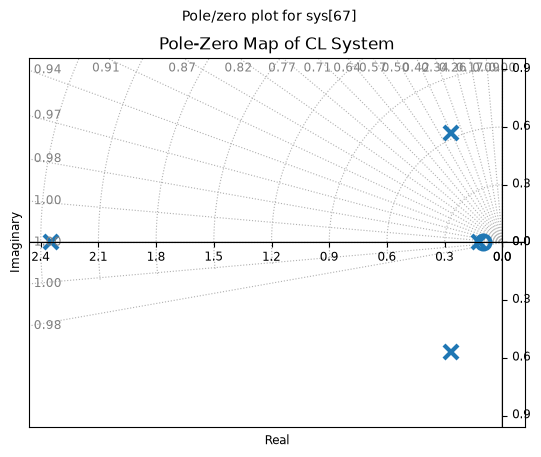

DC gain for CL= 1.0
Zeros of CL= [-0.1+0.j]
Poles of CL= [-2.34405588+0.j         -0.26754072+0.57117858j -0.26754072-0.57117858j
 -0.12139268+0.j        ]
    Eigenvalue (pole)       Damping     Frequency
               -2.344             1         2.344
   -0.2675   +0.5712j        0.4242        0.6307
   -0.2675   -0.5712j        0.4242        0.6307
              -0.1214             1        0.1214
Natural frequency of poles (Wn) = [2.34405588 0.63073212 0.63073212 0.12139268]
Damping ratio zeta of poles (Z) = [1.         0.42417488 0.42417488 1.        ]
Poles = [-2.34405588+0.j         -0.26754072+0.57117858j -0.26754072-0.57117858j
 -0.12139268+0.j        ]
Poles of CL= [-2.34405588+0.j         -0.26754072+0.57117858j -0.26754072-0.57117858j
 -0.12139268+0.j        ]
Dominant stable CL pole(s): [-0.12139268+0.j]
Dominant CL pole (p1) = (-0.12139267962917095+0j)
Dominant CL pole (p1) in abs value = 0.12139267962917095


Dominant Pole: (-0.12139267962917095+0j)
Natural frequency (

In [32]:
# closed loop poles and zeros analysis 

# Plot the Pole-Zero map with the damping/frequency grid
ct.pole_zero_plot(A5, grid=True, marker_size=10, marker_width=3)
plt.title("Pole-Zero Map of CL System")
plt.show()

# DC gain 
dc = ct.dcgain(A5)
print(f'DC gain for CL= {dc}')
# Zeros 
z = ct.zeros(A5)
print(f'Zeros of CL= {z}')
# Poles 
p = ct.poles(A5)
print(f'Poles of CL= {p}')

# Print exact transient metrics derived from poles 
wn, zeta, poles = ct.damp(A5)
print(f'Natural frequency of poles (Wn) = {wn}')
print(f'Damping ratio zeta of poles (Z) = {zeta}')
print(f'Poles = {poles}')

# To find the dominant pole(s) of a control system plant, 
# you identify the poles (the roots of the denominator of the transfer function) that lie closest to the imaginary (jw) axis 
# or the origin in the s-plane, 
# provided other poles are sufficiently far away
print(f'Poles of CL= {p}')

tol = 1e-8
# keep only strictly stable poles (real part < 0)
stable_mask = np.real(p) < -tol

if np.any(stable_mask):
    p_stable = p[stable_mask]
    rp = np.real(p_stable)
    max_rp = np.max(rp)
    dominant_poles = p_stable[np.isclose(rp, max_rp, atol=tol)]
else:
    dominant_poles = np.array([])
    print("No strictly stable pole -> no classical dominant pole.")

print("Dominant stable CL pole(s):", dominant_poles)

p1 = dominant_poles[0]
print(f'Dominant CL pole (p1) = {p1}')
print(f'Dominant CL pole (p1) in abs value = {np.abs(p1)}')
print('\n')

wn = abs(p1)                  # Natural frequency (rad/s)
zeta = -np.real(p1) / wn     # Damping ratio
sigma = -np.real(p1)         # Decay rate (1/s)
wd = abs(np.imag(p1))        # Damped frequency (rad/s)

print("Dominant Pole:", p1)
print("Natural frequency (wn):", wn, "rad/s")
print("Damping ratio (zeta, z):", zeta)
print("Decay rate (sigma):", sigma, "1/s")
print("Damped frequency (wd):", wd, "rad/s")




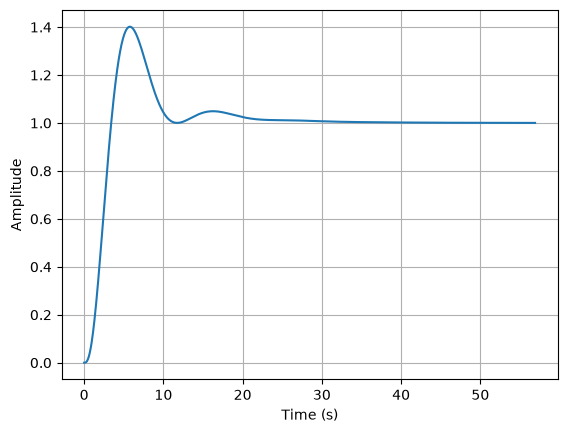

Rise Time (Tr): 2.12 seconds
Settling Time (Ts): 20.74 seconds
Peak Time (Tp): 5.77 seconds
Overshoot (%): 40.16%
Final Value = 1.0
Steasy state error (ess) = 0.0


In [33]:
plt.figure()
t, y = ct.step_response(A5)

plt.plot(t, y)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

# transient characteristics
info = ct.step_info(A5)
final_value = info['SteadyStateValue']
ess = 1 - final_value


print(f"Rise Time (Tr): {info['RiseTime']:.2f} seconds")
print(f"Settling Time (Ts): {info['SettlingTime']:.2f} seconds")
print(f"Peak Time (Tp): {info['PeakTime']:.2f} seconds")
print(f"Overshoot (%): {info['Overshoot']:.2f}%")
# print(f"Undershoot (%): {info['Undershoot']:.2f}%")
print(f'Final Value = {info["SteadyStateValue"]}')
print(f'Steasy state error (ess) = {ess}')

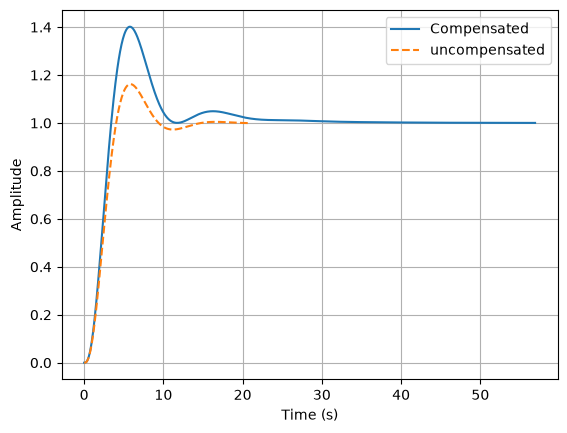

In [34]:
plt.figure()
t1, y1 = ct.step_response(A5)
t2, y2 = ct.step_response(CL)

plt.plot(t1, y1, label='Compensated')
plt.plot(t2, y2, label='uncompensated', linestyle='--')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.legend()
plt.show()